In [45]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [46]:
df = pd.read_csv("student-mat.csv")

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [48]:
# check for duplicates
df[df.duplicated()]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3


There are no duplicates and no missing values in this dataset.

The 10 columns of binary data in this set are currently saved as strings. In the following section, I'm going to change those datatypes.

Affected Columns:
- address (urban (U) or rural (R))
- Pstatus (living together (T) or apart (A))
- schoolsup (Y/N)
- famsup (Y/N)
- paid (Y/N)
- activities (Y/N)
- nursery (Y/N)
- higher (Y/N)
- internet (Y/N)
- romantic (Y/N)

In [49]:
# convert strings to bool
df['address'] = df['address'].replace({'U': True, 'R': False}).astype(bool)
df['Pstatus'] = df['Pstatus'].replace({'T': True, 'A': False}).astype(bool)
df['schoolsup'] = df['schoolsup'].replace({'Y': True, 'N': False}).astype(bool)
df['famsup'] = df['famsup'].replace({'Y': True, 'N': False}).astype(bool)
df['paid'] = df['paid'].replace({'Y': True, 'N': False}).astype(bool)
df['activities'] = df['activities'].replace({'Y': True, 'N': False}).astype(bool)
df['nursery'] = df['nursery'].replace({'Y': True, 'N': False}).astype(bool)
df['higher'] = df['higher'].replace({'Y': True, 'N': False}).astype(bool)
df['internet'] = df['internet'].replace({'Y': True, 'N': False}).astype(bool)
df['romantic'] = df['romantic'].replace({'Y': True, 'N': False}).astype(bool)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    bool 
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    bool 
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    bool 
 16  famsup      395 non-null    bool 
 17  paid        395 non-null    bool 
 18  activities  395 non-null    bool 
 19  nursery     395 non-null    bool 
 20  higher      395 non-null    bool 
 21  inte

Our research concerns the relationship between study time and grades, and there are many columns in this dataset that are irrelevant to both, so we can drop them. As of right now, we're keeping the variables that tell us about students' grades, what kind of support they get in their studies, and what they may be spending their time on.

In [50]:
df = df.drop(columns=['school','sex','age', 'address', 'Mjob', 'Fjob', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'reason', 
                      'guardian', 'famrel', 'goout'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   traveltime  395 non-null    int64
 1   studytime   395 non-null    int64
 2   failures    395 non-null    int64
 3   schoolsup   395 non-null    bool 
 4   famsup      395 non-null    bool 
 5   paid        395 non-null    bool 
 6   activities  395 non-null    bool 
 7   nursery     395 non-null    bool 
 8   higher      395 non-null    bool 
 9   internet    395 non-null    bool 
 10  romantic    395 non-null    bool 
 11  freetime    395 non-null    int64
 12  Dalc        395 non-null    int64
 13  Walc        395 non-null    int64
 14  health      395 non-null    int64
 15  absences    395 non-null    int64
 16  G1          395 non-null    int64
 17  G2          395 non-null    int64
 18  G3          395 non-null    int64
dtypes: bool(8), int64(11)
memory usage: 37.2 KB


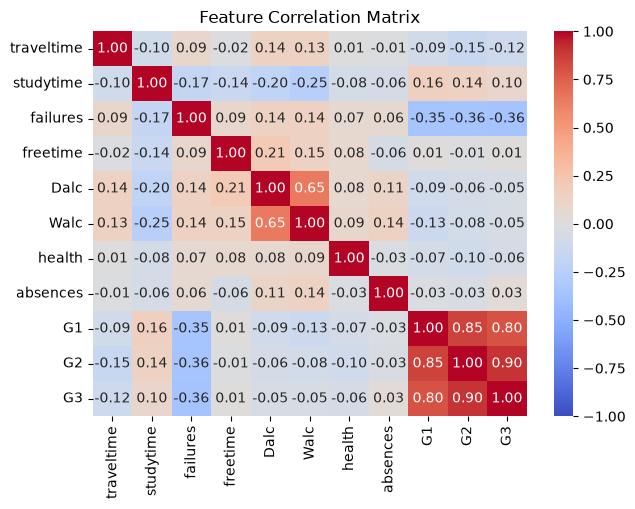

In [54]:
# create a heatmap to show the correlation between all of this dataset's numerical features
# NOTE: heatmaps are good for showing linear relationships, but not many others
plt.figure(figsize=(7, 5))
numeric_cols = df.select_dtypes(include=["number"])
sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin = -1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.show()